In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
from scipy.stats import pearsonr

# Load datasets
df = pd.read_csv("merged_weather_pca.csv")


In [2]:
# Step 1.5: Check how many rows have missing PC1_mean or total_precip_30d
missing_mask = df[["PC1_mean", "total_precip_30d"]].isna().any(axis=1)
missing_rows = df[missing_mask]

print(f"⚠️ Dropping {missing_rows.shape[0]} rows due to missing PC1_mean or total_precip_30d.\n")
print("Dropped rows:")
print(missing_rows[["taxa_name", "PC1_mean", "total_precip_30d", "Ecology"]])

# Drop missing rows
filtered_df = df.dropna(subset=["PC1_mean", "total_precip_30d"])



⚠️ Dropping 50 rows due to missing PC1_mean or total_precip_30d.

Dropped rows:
       taxa_name  PC1_mean  total_precip_30d Ecology
1175  A_gymnopus       NaN           306.000     NaN
1176  A_gymnopus       NaN           280.100     NaN
1177  A_gymnopus       NaN           220.300     NaN
1178  A_gymnopus       NaN           328.900     NaN
1179  A_gymnopus       NaN           174.800     NaN
1180  A_gymnopus       NaN           293.000     NaN
1181  A_gymnopus       NaN           338.500     NaN
1182  A_gymnopus       NaN           289.500     NaN
1183  A_gymnopus       NaN           293.700     NaN
1184  A_gymnopus       NaN           298.800     NaN
1185  A_gymnopus       NaN           256.700     NaN
1186  A_gymnopus       NaN           262.000     NaN
1187  A_gymnopus       NaN           289.200     NaN
1188  A_gymnopus       NaN           216.500     NaN
1189  A_gymnopus       NaN           198.700     NaN
1190  A_gymnopus       NaN           269.200     NaN
1191  A_gymnopus   

WARNING THIS NEXT ONE IS THROWING OUT A BUNCH OF DATA

In [3]:
# Step 1: Find taxa with any outlier datapoints
taxa_with_outliers = filtered_df.loc[filtered_df["zscore_mean_precip"].abs() >= 2, "taxa_name"].unique()

print(f"Taxa with any datapoints above Z=2: {taxa_with_outliers}")

# Step 2: Drop all rows for those taxa
filtered_z_df = filtered_df[~filtered_df["taxa_name"].isin(taxa_with_outliers)].reset_index(drop=True)

print(f"Filtered to {filtered_z_df.shape[0]} rows after dropping all taxa with any |Z| >= 2 for mean_precip_30d.")
print("Remaining taxa:", filtered_z_df["taxa_name"].unique())

Taxa with any datapoints above Z=2: ['A_aliena' 'A_alliacea' 'A_amanitoides' 'A_ameghinoi' 'A_ananaeceps'
 'A_areolata' 'A_atkinsoniana' 'A_augusta' 'A_aureofloccosa'
 'A_austroviridis' 'A_basiorubra' 'A_berkeleyi' 'A_boliviana'
 'A_borneensis' 'A_brunneiphylla' 'A_californica' 'A_carneiphylla'
 'A_centunculus' 'A_chatamagotake' 'A_chlorinosma' 'A_cinereoconia'
 'A_cinereopannosa' 'A_cingulata' 'A_coacta' 'A_codinae' 'A_cokeri'
 'A_concentrica' 'A_conicobulbosa' 'A_crassa' 'A_crassiconus'
 'A_crassifolia' 'A_daucipes' 'A_djarilmari' 'A_gracilior' 'A_grallipes'
 'A_griseibrunnea' 'A_griseofarinosa' 'A_griseoverrucosa'
 'A_heishidingensis' 'A_hesleri' 'A_ibotengutake' 'A_inodora' 'A_japonica'
 'A_javanica' 'A_kalamundae' 'A_kitamagotake' 'A_lanosa' 'A_lanosula'
 'A_lilloi' 'A_lippiae' 'A_lutescens' 'A_macrocarpa' 'A_madagascariensis'
 'A_malayensis' 'A_marmorata' 'A_masasiensis' 'A_microlepis' 'A_millsii'
 'A_nana' 'A_nauseosa' 'A_nitida' 'A_ochrophylla' 'A_ochroterrea'
 'A_odorata' 'A_o

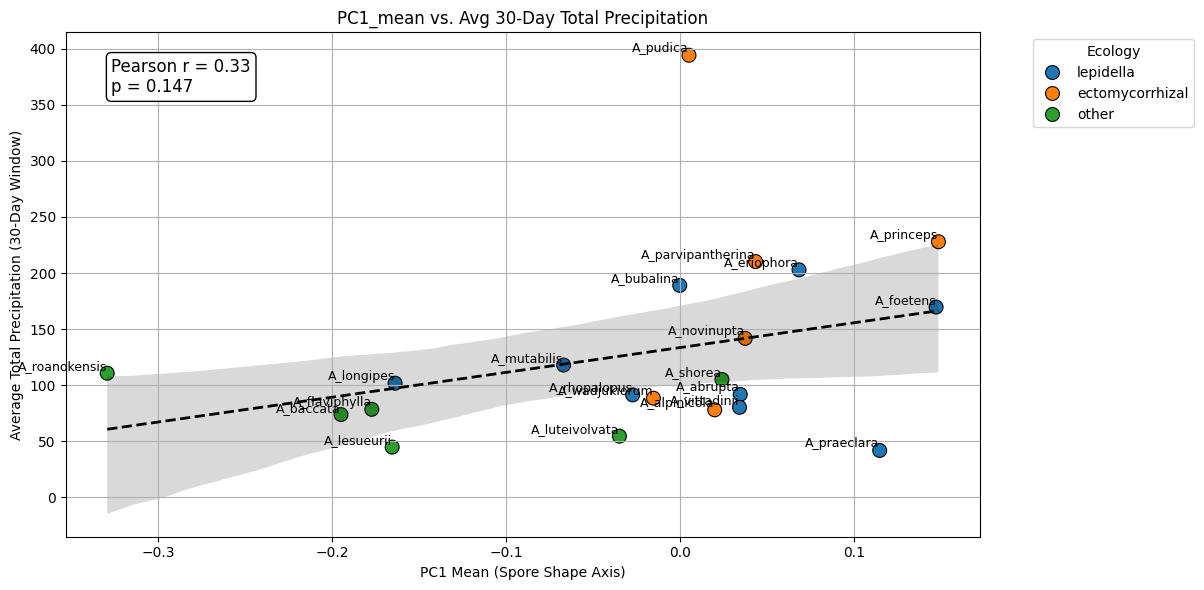

In [5]:

# Step 1: Aggregate total precipitation per taxon
agg_df = filtered_z_df.groupby("taxa_name").agg({
    "total_precip_30d": "mean",
    "PC1_mean": "first",
    "Ecology": "first"
}).reset_index()

# Step 2: Calculate Pearson correlation and p-value
r, p = pearsonr(agg_df["PC1_mean"], agg_df["total_precip_30d"])

# Step 3: Create the scatterplot with trendline
plt.figure(figsize=(10, 6))

# Plot points
sns.scatterplot(data=agg_df, x="PC1_mean", y="total_precip_30d", hue="Ecology", s=100, edgecolor="black")

# Add taxa_name labels to each point
for i, row in agg_df.iterrows():
    plt.text(
        row["PC1_mean"], row["total_precip_30d"], row["taxa_name"],
        fontsize=9, ha='right', va='bottom'
    )
    
# Add regression trendline (without confidence interval)
sns.regplot(
    data=agg_df,
    x="PC1_mean",
    y="total_precip_30d",
    scatter=False,
    color="black",
    line_kws={"linewidth": 2, "linestyle": "--"}
)

# Step 4: Annotate r and p values directly on the plot
plt.text(
    0.05, 0.95,
    f"Pearson r = {r:.2f}\np = {p:.3f}",
    transform=plt.gca().transAxes,
    ha='left',
    va='top',
    fontsize=12,
    bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
)

# Final plot settings
plt.title("PC1_mean vs. Avg 30-Day Total Precipitation")
plt.xlabel("PC1 Mean (Spore Shape Axis)")
plt.ylabel("Average Total Precipitation (30-Day Window)")
plt.grid(True)
plt.tight_layout()
plt.legend(title="Ecology", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


In [ ]:
# Step 1: Aggregate average precipitation per taxon
agg_df = filtered_z_df.groupby("taxa_name").agg({
    "total_precip_30d": "mean",
    "PC1_mean": "first",
    "Ecology": "first"
}).reset_index()

# --- Outlier Detection using IQR ---
Q1 = agg_df["total_precip_30d"].quantile(0.25)
Q3 = agg_df["total_precip_30d"].quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = agg_df[(agg_df["total_precip_30d"] < lower_bound) | (agg_df["total_precip_30d"] > upper_bound)]

print(f"Identified {outliers.shape[0]} outlier(s) in total_precip_30d:")
print(outliers[["taxa_name", "total_precip_30d", "PC1_mean", "Ecology"]])

# Optionally, add a column to flag outliers
agg_df["is_outlier"] = ((agg_df["total_precip_30d"] < lower_bound) | (agg_df["total_precip_30d"] > upper_bound))


In [ ]:
# Step 1: Aggregate average precipitation per taxon
agg_df = filtered_df.groupby("taxa_name").agg({
    "mean_precip_30d": "mean",
    "PC1_mean": "first",
    "Ecology": "first"
}).reset_index()

# --- Outlier Detection using IQR ---
Q1 = agg_df["mean_precip_30d"].quantile(0.25)
Q3 = agg_df["mean_precip_30d"].quantile(0.75)
IQR = Q3 - Q1

# Define outlier bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers
outliers = agg_df[(agg_df["mean_precip_30d"] < lower_bound) | (agg_df["mean_precip_30d"] > upper_bound)]

print(f"Identified {outliers.shape[0]} outlier(s) in mean_precip_30d:")
print(outliers[["taxa_name", "mean_precip_30d", "PC1_mean", "Ecology"]])

# Optionally, add a column to flag outliers
agg_df["is_outlier"] = ((agg_df["mean_precip_30d"] < lower_bound) | (agg_df["mean_precip_30d"] > upper_bound))